# Step 5. 피처 엔지니어링 · 변수 중요도 · API 서빙 마무리

- **예상 소요 시간:** 약 60분
- **목표:**
  1. **가설 검증의 정석:** 새 피처를 추가했을 때 **안 좋아지면 과감히 버리는** 실전 실험 과정을 체험한다.
  2. **부스팅 모델(`HistGradientBoostingRegressor`)** + **운영 DB 과거 이력 피처(어제·1주전·2주전 같은 시간 대여량)**로 최종 오차를 **`43.62대`**까지 낮춘다.
  3. **변수 중요도(Permutation Importance)**로 모델이 어떤 컬럼을 제일 많이 보고 예측하는지 해석한다.
  4. 학습된 모델을 파일로 저장(`joblib`)하고, **Spring 서버에서 ML 모델을 호출하는 실무 서빙 구조**를 정리한다.

---

### 백엔드 개발자 관점: 피처 엔지니어링(Feature Engineering)이란?
거창한 용어지만 별거 아니다.  
**Raw DB 테이블에 없는 유용한 파생 컬럼을 쿼리나 DTO 가공 단계에서 만들어 모델에 넘겨주는 작업**이다.

단, 여기서도 **데이터 누수 원칙**은 절대 깨면 안 된다.
- ❌ 내일 날씨 실제 관측치, 내일 비회원 대여량 → 예측 시점에 모름 (불법!)
- ⭕ **어제 같은 시간 대여량(`cnt_prev_day`), 1주 전 같은 요일·같은 시간 대여량(`cnt_prev_week`), 2주 전(`cnt_prev_2week`)** → 이미 우리 운영 DB에 저장돼 있는 과거 기록! (100% 합법 + 실무 최강 피처!)

In [1]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("dataset", exist_ok=True)
if not os.path.exists("dataset/hour.csv"):
    url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
    zip_path = "dataset/bike_sharing_dataset.zip"
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall("dataset")

df = pd.read_csv("dataset/hour.csv")

# Step 3에서 확정한 시계열 분할 기준 고정 (2012-09-01)
clean_cols = [
    "season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
    "weathersit", "temp", "atemp", "hum", "windspeed"
]
split_date = "2012-09-01"
train_df = df[df["dteday"] < split_date].copy()
test_df = df[df["dteday"] >= split_date].copy()

X_train, y_train = train_df[clean_cols], train_df["cnt"]
X_test, y_test = test_df[clean_cols], test_df["cnt"]

print(f"Train: {len(train_df):,}행 | Test: {len(test_df):,}행")

Train: 14,491행 | Test: 2,888행


---
## 1. 실패도 기록한다 — 달력 파생변수를 넣으면 무조건 좋아질까?

먼저 떠오르는 아이디어 2개를 `RandomForest`(현재 최고 기록 **`47.48대`**)에 붙여보자.
1. `is_rush_hour`: 평일 출퇴근 시간(7~9시, 17~19시)이면 `1`, 아니면 `0`
2. `hr_sin`, `hr_cos`: 23시와 0시가 숫자상 멀리 떨어져 있지만 실제론 1시간 차이라는 걸 알려주는 주기(원형) 인코딩

> **[실행 전 예측]**  
> 이 3개 컬럼을 추가하면 `RandomForest`의 Test MAE(`47.48대`)가 확실히 줄어들까? 아니면 비슷하거나 오히려 살짝 나빠질까?

In [2]:
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor

def add_calendar_features(data):
    d = data.copy()
    # 1) 평일 출퇴근 시간대 여부 (True/False -> 1/0)
    d["is_rush_hour"] = (
        (d["workingday"] == 1) & (d["hr"].isin([7, 8, 9, 17, 18, 19]))
    ).astype(int)
    # 2) 시간(0~23)의 주기 인코딩 (23시와 0시가 가깝다는 표현)
    d["hr_sin"] = np.sin(2 * np.pi * d["hr"] / 24)
    d["hr_cos"] = np.cos(2 * np.pi * d["hr"] / 24)
    return d

df_cal = add_calendar_features(df)
cal_cols = clean_cols + ["is_rush_hour", "hr_sin", "hr_cos"]

tr_cal = df_cal[df_cal["dteday"] < split_date]
te_cal = df_cal[df_cal["dteday"] >= split_date]

rf_cal = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_cal.fit(tr_cal[cal_cols], tr_cal["cnt"])
mae_rf_cal = mean_absolute_error(te_cal["cnt"], rf_cal.predict(te_cal[cal_cols]))

print(f"[Exp 4b] 기존 RandomForest (12컬럼)      → Test MAE: 47.48대")
print(f"[실험]   RF + 달력/주기 피처 (+3컬럼)    → Test MAE: {mae_rf_cal:.2f}대")

[Exp 4b] 기존 RandomForest (12컬럼)      → Test MAE: 47.48대
[실험]   RF + 달력/주기 피처 (+3컬럼)    → Test MAE: 47.72대


### 🔍 코드 뜯어보기
- **`d["hr"].isin([7, 8, 9, 17, 18, 19])`:**  
  SQL의 `WHERE hr IN (7, 8, 9, 17, 18, 19)`과 100% 같다. 결과는 `True/False`이고, 뒤에 `.astype(int)`를 붙여 모델이 먹기 좋게 `1/0` 정수로 변환한다.
- **`np.sin(2 * np.pi * d["hr"] / 24)` & `np.cos(...)`:**  
  24시간을 시계(원, $2\pi$ 라디안) 위에 올려놓는 공식이다. 선형회귀나 신경망에서는 효과가 크지만, 트리 모델은 원래도 `hr >= 7`처럼 숫자를 잘게 쪼개기 때문에 효과가 미미할 수 있다.

### 결과 해석: 안 좋아졌으면 과감히 버린다!
- `47.48대` → **`47.72대`**로 오히려 0.24대 나빠졌다.
- 왜? 트리 모델(`RandomForest`)은 이미 기존 `workingday`와 `hr` 컬럼만으로 출퇴근 시간대를 충분히 잘 쪼개고 있었기 때문이다. 불필요한 중복 컬럼만 늘어나면 트리 선택에 노이즈가 생긴다.
- **실무 습관:** 피처를 추가했는데 점수가 안 오르면 미련 없이 **롤백(Git revert)**한다. "이걸 해봤는데 트리 모델엔 효과가 없어서 뺐다"고 말할 수 있는 것도 훌륭한 발표 소재다.

---
## 2. 진짜 성능 올리기 ① — 모델 교체 (`HistGradientBoostingRegressor`)

RandomForest는 나무 100그루가 **각자 독립적으로** 공부한 뒤 평균을 낸다(**배깅, Bagging**).  
반면 **그래디언트 부스팅(Gradient Boosting)**은 **1번 나무가 틀린 오차를 2번 나무가 고치고, 2번이 틀린 오차를 3번이 고치는 식**으로 순차적으로 약점을 보완한다. (정형 데이터 실무 1티어인 LightGBM·XGBoost가 바로 이 방식이다.)

`scikit-learn`에 기본 내장된 **`HistGradientBoostingRegressor`**는 LightGBM과 거의 같은 알고리즘이라 별도 설치 없이 바로 쓸 수 있고, 결측치(`NaN`)도 알아서 처리한다.

> **[실행 전 예측]**  
> 피처는 기존 12개 그대로 두고 모델만 `RandomForest(47.48대)` → `HistGradientBoosting`으로 바꾼다. 오차가 얼마나 줄어들까?

In [3]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_base = HistGradientBoostingRegressor(
    max_iter=300,        # 순차적으로 만들 나무 개수 (오차 보완 횟수)
    learning_rate=0.05,  # 한 번에 오차를 얼마나 조심스럽게 고칠지 (작을수록 꼼꼼)
    random_state=42
)
hgb_base.fit(X_train, y_train)
pred_hgb_base = hgb_base.predict(X_test)
mae_hgb_base = mean_absolute_error(y_test, pred_hgb_base)

print(f"[Exp 4b] RandomForest (12컬럼)         → Test MAE: 47.48대")
print(f"[Exp 5a] HistGradientBoosting (12컬럼) → Test MAE: {mae_hgb_base:.2f}대")

[Exp 4b] RandomForest (12컬럼)         → Test MAE: 47.48대
[Exp 5a] HistGradientBoosting (12컬럼) → Test MAE: 45.11대


### 🔍 코드 뜯어보기
- **`max_iter=300`:** 오차를 고치는 나무를 최대 300단계까지 이어 붙인다.
- **`learning_rate=0.05`:** 학습률. 한 나무가 틀린 오차를 한 번에 100% 고치려고 하면 과적합되므로, 5%(`0.05`)씩 조금씩 여러 번 보완한다. (실무에서 `learning_rate`를 `0.05`로 낮추고 `max_iter`를 `300~500`으로 늘리는 조합을 자주 쓴다.)

---
## 3. 진짜 성능 올리기 ② — 운영 DB 과거 이력 피처(Lag Feature) 붙이기

Step 1에서 발견한 사실을 기억하자: **2011년 → 2012년 사이 서비스가 +63% 성장했다.**  
오늘 아침 8시 대여량을 맞추려면, 날씨보다 **"어제 아침 8시엔 몇 대 탔고, 지난주 같은 요일 아침 8시엔 몇 대 탔는지"**를 운영 DB에서 조회해 넘겨주는 게 훨씬 강력하다!

Step 1에서 확인했듯 중간에 빠진 시간(165시간)이 있으므로, 단순 `.shift(24)` 대신 **날짜 자체를 `+1일`, `+7일`, `+14일` 밀어서 SQL LEFT JOIN(`pd.merge`)**으로 정확하게 매칭한다. (이 방식이 누락 시간에도 절대 밀리지 않는 실무 정석이다!)

In [4]:
# 날짜 문자열을 datetime 타입으로 변환 (날짜 덧셈을 위해 필수)
df_lag = df.copy()
df_lag["dteday_dt"] = pd.to_datetime(df_lag["dteday"])

# 조회용 기준 테이블 (날짜, 시간, 대여량)
lookup = df_lag[["dteday_dt", "hr", "cnt"]].copy()

# SQL LEFT JOIN 방식으로 1일 전, 7일 전, 14일 전 같은 시간 대여량 붙이기
for days, col_name in [(1, "cnt_prev_day"), (7, "cnt_prev_week"), (14, "cnt_prev_2week")]:
    shifted = lookup.copy()
    # 과거 기록의 날짜에 +days를 더하면, 현재 행의 날짜와 정확히 매칭된다!
    shifted["dteday_dt"] = shifted["dteday_dt"] + pd.Timedelta(days=days)
    shifted = shifted.rename(columns={"cnt": col_name})
    df_lag = df_lag.merge(shifted, on=["dteday_dt", "hr"], how="left")

# 잘 붙었는지 샘플 5줄 확인 (2012-09-01 기준)
print("[과거 이력 피처 조인 확인]")
print(df_lag[df_lag["dteday"] == "2012-09-01"][["dteday", "hr", "cnt", "cnt_prev_day", "cnt_prev_week", "cnt_prev_2week"]].head(5))

# 시계열 분할 & 최종 모델 학습
lag_cols = clean_cols + ["cnt_prev_day", "cnt_prev_week", "cnt_prev_2week"]
tr_lag = df_lag[df_lag["dteday"] < split_date]
te_lag = df_lag[df_lag["dteday"] >= split_date]

hgb_final = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    random_state=42
)
hgb_final.fit(tr_lag[lag_cols], tr_lag["cnt"])
pred_final = hgb_final.predict(te_lag[lag_cols])
mae_final = mean_absolute_error(te_lag["cnt"], pred_final)

print(f"\n[Exp 5a] HistGradientBoosting (12컬럼)          → Test MAE: {mae_hgb_base:.2f}대")
print(f"[Exp 5b] HistGradientBoosting + 과거이력 (15컬럼) → Test MAE: {mae_final:.2f}대  <-- 최종 최고 기록!")

[과거 이력 피처 조인 확인]
           dteday  hr  cnt  cnt_prev_day  cnt_prev_week  cnt_prev_2week
14491  2012-09-01   0  168          82.0          135.0           105.0
14492  2012-09-01   1   79          32.0          115.0            92.0
14493  2012-09-01   2   69          20.0           79.0            43.0
14494  2012-09-01   3   35           5.0           38.0            30.0
14495  2012-09-01   4   12           7.0           12.0            13.0

[Exp 5a] HistGradientBoosting (12컬럼)          → Test MAE: 45.11대
[Exp 5b] HistGradientBoosting + 과거이력 (15컬럼) → Test MAE: 43.62대  <-- 최종 최고 기록!


### 🔍 코드 뜯어보기
- **`pd.to_datetime(df_lag["dteday"])` + `pd.Timedelta(days=days)`:**  
  문자열 `'2012-09-01'`을 날짜 객체(`LocalDate` 같은 타입)로 바꾼 뒤, `days`일만큼 더한다.
- **왜 과거 기록 날짜에 `+1일`을 더해서 조인할까? (핵심 트릭!)**  
  - 예를 들어 8월 31일 08시(`cnt=400`) 행의 날짜에 `+1일`을 더하면 `9월 1일 08시`가 된다.
  - 이걸 원본 테이블의 `9월 1일 08시` 행과 `LEFT JOIN`하면, 9월 1일 행 옆에 `cnt_prev_day=400`(어제 8시 대여량)이 정확히 붙는다!
  - SQL로 쓰면 아래와 100% 같다:
    ```sql
    SELECT a.*, b.cnt AS cnt_prev_day
    FROM hour a
    LEFT JOIN hour b
      ON a.dteday = DATE_ADD(b.dteday, INTERVAL 1 DAY)
     AND a.hr = b.hr;
    ```
- **조인 후 생긴 `NaN`(초기 1~14일, 또는 전날 누락 시간)은 왜 안 채웠을까?**  
  `HistGradientBoostingRegressor`는 `NaN`을 에러 없이 자체 분기 조건으로 처리한다! (`RandomForest`나 `LinearRegression`에 넣을 때는 학습셋 중앙값 등으로 채워야 한다.)

---
## 4. 모델 해석 — 어떤 컬럼이 예측에 제일 큰 영향을 줬을까?

"모델 오차가 43.62대입니다"로 끝내면 기획팀이 묻는다.  
**"그래서 자전거 대여량에 제일 큰 영향을 주는 게 날씨예요, 시간이에요, 지난주 기록이에요?"**

**Permutation Importance(순열 중요도)**로 답할 수 있다. 원리는 아주 직관적이다.
> *"테스트 데이터에서 특정 컬럼 하나(예: `hr`)의 값만 랜덤으로 마구 뒤섞어 망가뜨렸을 때, 모델 오차(MAE)가 몇 대나 폭등하는지 재는 방법"*  
> → 망가뜨렸을 때 오차가 확 치솟는 컬럼일수록 **모델이 크게 의존하는 핵심 변수**다!

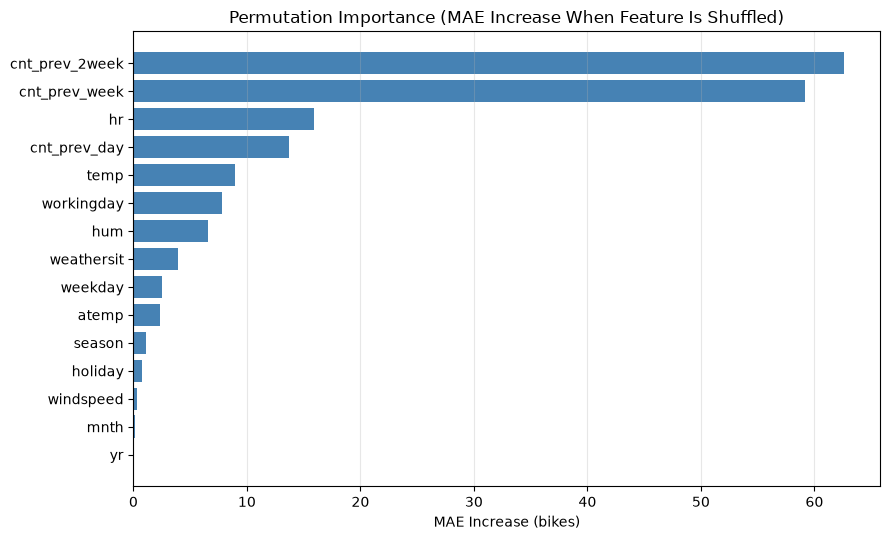

[변수 중요도 TOP 5 (해당 컬럼을 망가뜨렸을 때 늘어나는 평균 오차 대수)]
cnt_prev_2week    62.65
cnt_prev_week     59.21
hr                15.89
cnt_prev_day      13.70
temp               8.97
dtype: float64


In [5]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    hgb_final,
    te_lag[lag_cols],
    te_lag["cnt"],
    scoring="neg_mean_absolute_error",  # sklearn은 점수가 클수록 좋다고 가정해서 MAE에 마이너스(-)를 붙임
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

imp_series = pd.Series(perm.importances_mean, index=lag_cols).sort_values(ascending=True)

plt.figure(figsize=(9, 5.5))
plt.barh(imp_series.index, imp_series.values, color="steelblue")
plt.title("Permutation Importance (MAE Increase When Feature Is Shuffled)")
plt.xlabel("MAE Increase (bikes)")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("[변수 중요도 TOP 5 (해당 컬럼을 망가뜨렸을 때 늘어나는 평균 오차 대수)]")
print(imp_series.sort_values(ascending=False).head(5).round(2))

### 🔍 코드 뜯어보기
- **`scoring="neg_mean_absolute_error"`:**  
  `sklearn` 내부 규칙상 모든 `scoring`은 **"숫자가 클수록 좋은 모델"**이어야 한다. 그런데 MAE는 작을수록 좋기 때문에 `-MAE`를 지표로 넘긴다. 다행히 `permutation_importance`가 차이를 계산할 때 부호가 뒤집혀서, 최종 `importances_mean` 값은 직관적으로 **"이 컬럼을 망가뜨렸을 때 늘어난 MAE(대수)"**로 나온다.
- **`n_repeats=5`:** 랜덤 섞기를 1번만 하면 운에 좌우될 수 있으니 5번 반복해서 평균을 낸다.
- **`plt.barh(...)`:** 가로 막대 그래프(`bar` + `h`orizontal). 컬럼 이름이 길 때는 세로 막대보다 가로 막대가 훨씬 읽기 편하다.

---
## 5. Spring 개발자를 위한 마무리 — 모델 저장 & API 서빙 구조

학습한 모델은 노트북 안에만 두면 아무 소용이 없다. 파일 1개로 저장(`joblib.dump`)해 두고, 예측 요청이 올 때마다 불러서 추론한다.

### 실무 서빙 아키텍처 (Spring + Python 모델)
```text
[클라이언트]
     │  POST /api/v1/predict-rentals (날짜, 시간, 예보 날씨)
     ▼
[Spring Boot API 서버]
     │  1) DB에서 어제/1주전/2주전 같은 시간 대여량 조회 (cnt_prev_day/week/2week)
     │  2) Python 추론 서버(FastAPI)로 15개 피처 JSON 전송
     ▼
[FastAPI ML 추론 서버]
     │  joblib.load("bike_hgb_model.joblib") → model.predict(...)
     ▼
[Spring Boot] → 음수 방지(Math.max(0, pred)) 후 최종 응답 반환
```
아래 코드로 실제 모델 저장 → 재로딩 → 단건 API 요청 예측까지 테스트해 보자.

In [6]:
import joblib

# 1) 학습된 모델 파일로 저장 (Spring의 빌드 산출물 .jar 만드는 단계와 같음)
model_path = "dataset/bike_hgb_model.joblib"
joblib.dump(hgb_final, model_path)
print(f"모델 저장 완료: {model_path} ({os.path.getsize(model_path) / 1024:.1f} KB)")

# 2) 서버 기동 시 모델 로딩 (실무에서는 앱 시작할 때 메모리에 1번만 로드!)
loaded_model = joblib.load(model_path)

# 3) API 요청 1건 들어왔다고 가정하고 예측 함수 테스트
def predict_bike_rentals(request_dto: dict) -> int:
    # 1건짜리 딕셔너리를 1행 DataFrame으로 변환 (학습 때와 똑같은 컬럼 순서 보장!)
    input_df = pd.DataFrame([request_dto])[lag_cols]
    raw_pred = loaded_model.predict(input_df)[0]
    # 도메인 규칙: 대여량은 0 이상 정수
    return max(0, int(round(raw_pred)))

sample_request = {
    "season": 4, "yr": 1, "mnth": 10, "hr": 8,
    "holiday": 0, "weekday": 2, "workingday": 1,
    "weathersit": 1, "temp": 0.48, "atemp": 0.47, "hum": 0.65, "windspeed": 0.15,
    "cnt_prev_day": 510, "cnt_prev_week": 540, "cnt_prev_2week": 525
}

predicted_bikes = predict_bike_rentals(sample_request)
print(f"[API 추론 테스트] 내일(평일 맑은 날 08시) 예상 대여량: {predicted_bikes}대")

모델 저장 완료: dataset/bike_hgb_model.joblib (1071.0 KB)
[API 추론 테스트] 내일(평일 맑은 날 08시) 예상 대여량: 580대


### 🔍 코드 뜯어보기
- **`joblib.dump` / `joblib.load`:**  
  학습이 끝난 파이썬 모델 객체를 바이너리 파일로 직렬화/역직렬화한다. Java의 `ObjectOutputStream` / Jackson 직렬화와 같은 역할이다. (용량도 약 1MB 수준으로 아주 가볍다!)
- **`pd.DataFrame([request_dto])[lag_cols]`:**  
  - 딕셔너리 1개를 리스트 `[...]`로 감싸면 **1행짜리 2차원 표**가 된다.
  - 뒤에 `[lag_cols]`를 꼭 붙이는 이유: API JSON 키 순서가 뒤바뀌어 들어와도 **학습할 때와 100% 똑같은 컬럼 순서**로 정렬해서 모델에 넘기기 위해서다. (순서가 어긋나면 조용히 엉뚱한 예측을 뱉는 치명적 버그가 난다!)
- **`loaded_model.predict(input_df)[0]`:**  
  `.predict()`는 항상 배열을 반환하므로 단건 결과는 `[0]`으로 첫 번째 값을 꺼낸다.

---
## 6. 직접 해보는 자습 미션 (10분)

- **미션 1:** 위 `sample_request`에서 **`weathersit`만 `1(맑음)` → `3(비/눈)`**으로 바꿨을 때 예상 대여량이 몇 대에서 몇 대로 줄어드는지 확인해 보자.
- **미션 2:** 이번엔 **`workingday`를 `0(주말)`**, **`hr`을 `14(오후 2시)`**로 바꿔서 테스트해 보자.

In [ ]:
# [미션 1 & 2] sample_request의 날씨와 시간/평일 여부를 바꿔 API 추론 테스트하기
# TODO: sample_request.copy() 로 복사해서 값을 바꾼 뒤 predict_bike_rentals()를 호출해 보세요.

<details>
<summary>정답 코드 보기</summary>

```python
# 미션 1: 비/눈 오는 평일 아침 8시
rainy_req = sample_request.copy()
rainy_req["weathersit"] = 3
print(f"맑은 날 08시: {predict_bike_rentals(sample_request)}대 → 비 오는 날 08시: {predict_bike_rentals(rainy_req)}대")

# 미션 2: 맑은 주말 오후 2시
weekend_req = sample_request.copy()
weekend_req["workingday"] = 0
weekend_req["weekday"] = 6
weekend_req["hr"] = 14
print(f"주말 오후 2시 예상 대여량: {predict_bike_rentals(weekend_req)}대")
```
</details>

---
## 7. 전체 여정 최종 벤치마크 요약 (Step 1 ~ Step 5)

| 실험 번호 | 변경한 것 (딱 1개) | 평가 방식 | Test MAE (평균 오차) | 핵심 배운 점 |
| :---: | :--- | :--- | :---: | :--- |
| **Exp 0** | 무조건 평균값 찍기 (Baseline) | 시계열 분할 | **170.51대** | 성능 비교의 바닥 기준선 |
| **Exp 1** | 모든 컬럼 그대로 투입 (**함정 1**) | 랜덤 분할 | **0.00대** *(가짜)* | `casual+registered` 데이터 누수 버그 |
| **Exp 2** | 누수 제거 + RandomForest (**함정 2**) | 랜덤 분할 | **24.90대** *(가짜)* | 10시·12시 보고 11시 맞추는 미래 컨닝 |
| **Exp 3** | 분할 방식만 시계열로 교정 (**함정 3**) | 시계열 분할 | **136.23대** | 선형회귀(직선)로는 출퇴근 쌍봉 못 그림 |
| **Exp 4a** | 모델만 결정트리(DecisionTree)로 교체 | 시계열 분할 | **58.96대** | `Train 0.01 vs Test 58.96` 과적합 체감 |
| **Exp 4b** | 모델만 RandomForest로 교체 | 시계열 분할 | **47.48대** | 100그루 평균으로 과적합 완화 + 에러 분석 |
| **Exp 5a** | 모델만 Gradient Boosting으로 교체 | 시계열 분할 | **45.11대** | 오차를 순차 보완하는 부스팅 효과 |
| **Exp 5b** | DB 과거 이력 피처 3개 추가 (1d/7d/14d) | 시계열 분할 | **43.62대** | **최종 모델! 기준선 대비 오차 74% 감소** |

---
**Step 1 ~ Step 5 전체 자습 완료!**  
이제 같은 폴더의 **`PRESENTATION_30MIN.md`**를 열고, 방금 직접 확인한 숫자와 그래프로 30분 발표를 준비하면 된다.